<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and fixture design](README.md)

# 01 · Can a paged inventory support a complete regional review?

A resource inventory can lose important context twice: an incomplete page walk drops resources, and an inner join drops resources whose subscription label is unavailable. We will retain every returned resource, inspect location availability, and count which regional resources lie outside one illustrative target region.

**This is an explicitly synthetic estate, not an Azure export.** The published worker supplies its real catalog. A companion injects the repository's shipped `FakeArg` through the original function's client seam, exercising actual request construction, pagination and JSON-to-Arrow mapping. No Azure tenant, authentication or live service is used. The fixture recognizes two declared KQL strings; it does not implement KQL.

## Choose the page size and illustrative region

`PAGE_SIZE` is the requested number of rows per internal page, from 1 to 1000. It is **not a total row limit**. `TARGET_REGION` supplies a comparison label, not a compliance rule: resource type, redundancy, global scope and business requirements need separate judgment.

The end experiment changes only `PAGE_SIZE` from **2 to 5**. Predict fewer fixture requests with identical resource rows and regional classifications. Restart the kernel and Run All after editing.

In [1]:
PAGE_SIZE = 2  # Integer 1–1000; experiment: 5
TARGET_REGION = "eastus"  # Illustrative regional comparison; hold fixed for the experiment

In [2]:
import hashlib
import json
import math
import os
import tempfile
from datetime import datetime, timezone
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

assert isinstance(PAGE_SIZE,int) and not isinstance(PAGE_SIZE,bool) and 1 <= PAGE_SIZE <= 1000
assert TARGET_REGION in {"eastus","westus","westeurope"}, "Choose a declared fixture region"
fixture_hash=hashlib.sha256(Path("fixture.json").read_bytes()).hexdigest()
run_started=datetime.now(timezone.utc).isoformat()
scratch=tempfile.TemporaryDirectory(prefix="vgi-resourcegraph-notebook-")
trace_path=Path(scratch.name)/"posts.jsonl";trace_path.write_text("")
os.environ["VGI_RESOURCEGRAPH_FIXTURE_TRACE"]=str(trace_path)
os.environ["PLOOMBER_STATS_ENABLED"]="false"
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":125,"text.parse_math":False,"axes.spines.top":False,"axes.spines.right":False})
STATES=["Target region","Other region","Global","No location"]
COLORS={"Target region":"#247f9e","Other region":"#b88a29","Global":"#745b9e","No location":"#858585"}
def prose(text):display(Markdown(text))
def finish(fig):
    fig.text(.01,.01,"Source: synthetic fixture.json · original Resource Graph v0.4.0 function · no live tenant",fontsize=8,color="#555555")
    fig.tight_layout(rect=(0,.05,1,.95));plt.show()
fixture_secret_directory = tempfile.TemporaryDirectory(prefix="vgi-fixture-secrets-")
con = haybarn.connect(config={"secret_directory": fixture_secret_directory.name, "allow_persistent_secrets": False})
assert con.execute("SELECT name, persistent, storage FROM duckdb_secrets()").fetchall() == [], "Fixture must start without SQL secrets"
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline


/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-resourcegraph/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-resourcegraph/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-resourcegraph/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-resourcegraph/notebooks/pyproject.toml.

## Discover the published catalog, then attach the declared fixture

The native v0.4.0 release exposes a credential-free recipe menu. The companion fetches the **same release's immutable source commit**, installs frozen Bun dependencies and injects `FakeArg` into `makeResourceGraphFunction`. Runtime network fetch is disabled; only the two exact fixture queries at the Resource Graph query endpoint are accepted.

The dummy `azure_graph` secret satisfies the worker's lookup; the fixture ignores it. The query POST here is local and read-only. It does not contact Azure, mint a token or test RBAC.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'azure' AS published (
    TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-azure-resourcegraph@v0.4.0'
);
ATTACH 'azure' AS fixture (
    TYPE vgi,
    LOCATION 'bun run resourcegraph_fixture.ts Query-farm/vgi-azure-resourcegraph 738e894f9e55a9bf7cf3c10f11303757eceefc17 fixture.json'
);
CREATE TEMPORARY SECRET synthetic_fixture_input (
    TYPE azure_graph,
    TENANT_ID '00000000-0000-0000-0000-000000000000',
    CLIENT_ID '00000000-0000-0000-0000-000000000000',
    CLIENT_SECRET 'synthetic-not-a-credential'
);

,Success


In [4]:
fixture_secrets = con.execute("SELECT name, persistent, storage FROM duckdb_secrets() ORDER BY name").fetchall()
assert fixture_secrets == [('synthetic_fixture_input', False, 'memory')], "Only the public temporary fixture secrets may exist"

In [5]:
%%sql recipes <<
SELECT name,kql,description FROM published.main.kql_recipes ORDER BY name;

In [6]:
display(recipes)
prose(f"**Synthetic fixture SHA-256:** `{fixture_hash}`. **Execution began:** {run_started}. "
      "That is an execution timestamp, not an Azure source timestamp. The fixture is a fixed illustrative inventory. "
      "The menu above comes from the published worker; only the two queries used below are supported by this fixture.")

,name,kql,description
0,all_resources,"Resources | project name, type, location","Every resource with its name, type, and region."
1,count_by_resource_group,Resources | summarize count() by resourceGroup,Number of resources in each resource group.
2,count_by_type,Resources | summarize count() by type,Number of resources of each resource type.
3,public_ip_addresses,Resources | where type =~ 'microsoft.network/p...,Public IP address resources with their resourc...
4,storage_accounts,Resources | where type =~ 'microsoft.storage/s...,Storage accounts with their resource group and...
5,untagged_resources,Resources | where isnull(tags) or array_length...,Resources that carry no tags — useful for gove...
6,virtual_machines,Resources | where type =~ 'microsoft.compute/v...,Virtual machines with their resource group and...


**Synthetic fixture SHA-256:** `649a7f372bbb57a497573d380c32ecf4a7c08221040b2c449207e9cdb05bd2c9`. **Execution began:** 2026-11-14T10:57:00.930534+00:00. That is an execution timestamp, not an Azure source timestamp. The fixture is a fixed illustrative inventory. The menu above comes from the published worker; only the two queries used below are supported by this fixture.

## Materialize both complete scans

Resource Graph returns each projected object as one JSON string in `result`. Keep resource IDs and subscription IDs in the projection so the inventory can be checked and joined without relying on display names.

Each scan starts without a continuation token. The worker freezes the query identity and follows `$skipToken` until the response omits it. Tokens stay inside that scan: there is no cross-scan cursor, watermark or marker row. A refresh replaces the whole stored snapshot. Two live scans would not be an atomic joint snapshot; our two fixed synthetic datasets remain unchanged.

In [7]:
%%sql
CREATE TABLE resource_json AS
SELECT result FROM fixture.main.resourcegraph_query(
    'Resources | project id, name, type, location, subscriptionId',
    page_size := {{PAGE_SIZE}}
);
CREATE TABLE subscription_json AS
SELECT result FROM fixture.main.resourcegraph_query(
    'ResourceContainers | where type =~ ''microsoft.resources/subscriptions'' | project id, subscriptionId, name',
    page_size := {{PAGE_SIZE}}
);
CREATE TABLE resources AS
SELECT result->>'id' AS resource_id,result->>'name' AS resource_name,
       result->>'type' AS resource_type,result->>'subscriptionId' AS subscription_id,
       nullif(lower(trim(result->>'location')),'') AS location
FROM resource_json;
CREATE TABLE subscriptions AS
SELECT result->>'subscriptionId' AS subscription_id,result->>'name' AS subscription_name
FROM subscription_json;

,Count


In [8]:
%%sql availability <<
SELECT 'resources' AS dataset,count(*) AS rows,count(DISTINCT resource_id) AS distinct_ids,
       count(*) FILTER (WHERE resource_id IS NULL OR subscription_id IS NULL) AS missing_join_ids
FROM resources
UNION ALL
SELECT 'subscriptions',count(*),count(DISTINCT subscription_id),
       count(*) FILTER (WHERE subscription_id IS NULL)
FROM subscriptions;

In [9]:
display(availability)
assert (availability.rows==availability.distinct_ids).all() and (availability.missing_join_ids==0).all()
assert (availability.rows>0).all()
requests=[json.loads(line) for line in trace_path.read_text().splitlines()]
request_summary=[]
for dataset,prefix in [("resources","Resources |"),("subscriptions","ResourceContainers |")]:
    group=[r for r in requests if r["body"]["query"].startswith(prefix)]
    expected=int(availability.loc[availability.dataset==dataset,"rows"].iloc[0])
    assert len(group)==math.ceil(expected/PAGE_SIZE)
    assert "$skipToken" not in group[0]["body"]["options"] and not group[-1]["has_next"]
    assert all("$skipToken" in r["body"]["options"] for r in group[1:])
    assert all(r["body"]["options"]["$top"]==PAGE_SIZE for r in group)
    assert sum(r["response_rows"] for r in group)==expected
    request_summary.append({"dataset":dataset,"pages":len(group),"rows":expected})
request_table=pd.DataFrame(request_summary);display(request_table)
rows=con.execute("SELECT result FROM resource_json UNION ALL SELECT result FROM subscription_json ORDER BY result").fetchall()
result_hash=hashlib.sha256(json.dumps(rows,separators=(",",":")).encode()).hexdigest()
prose(f"Both page walks completed: **{len(requests)} query requests** returned **{sum(r['rows'] for r in request_summary)} total rows** "
      f"across the two datasets. IDs are unique within each dataset and join IDs are present. **Returned-row fingerprint:** `{result_hash}`. "
      "This demonstrates the worker's page walk against the declared fake; it does not establish live API completeness or latency.")

,dataset,rows,distinct_ids,missing_join_ids
0,resources,13,13,0
1,subscriptions,3,3,0


,dataset,pages,rows
0,resources,7,13
1,subscriptions,2,3


Both page walks completed: **9 query requests** returned **16 total rows** across the two datasets. IDs are unique within each dataset and join IDs are present. **Returned-row fingerprint:** `d3f41dca1815980bb77c5c0f2309f7b20c180757850c0d942cc84fb05bbcc8e8`. This demonstrates the worker's page walk against the declared fake; it does not establish live API completeness or latency.

## Preserve missing labels and location categories

A left join retains resources whose subscription metadata is unavailable. Unmatched labels stay visible as the subscription ID; they are not silently discarded or renamed as a known subscription.

Normalize location text, then separate global and missing locations from regional resources. The “outside target” fraction uses **only resources with a non-global declared region** as its denominator. It is a review description, not evidence of noncompliance.

In [10]:
%%sql
CREATE TABLE review AS
SELECT r.*,s.subscription_name,
       coalesce(s.subscription_name,'Unmatched: '||r.subscription_id) AS subscription_label,
       CASE WHEN r.location IS NULL THEN 'No location'
            WHEN r.location='global' THEN 'Global'
            WHEN r.location='{{TARGET_REGION}}' THEN 'Target region'
            ELSE 'Other region' END AS location_category
FROM resources r LEFT JOIN subscriptions s USING (subscription_id);

,Count


In [11]:
%%sql summary <<
SELECT count(*) AS total,
       count(*) FILTER (WHERE subscription_name IS NULL) AS unmatched,
       count(*) FILTER (WHERE location_category='Target region') AS in_target,
       count(*) FILTER (WHERE location_category='Other region') AS other_region,
       count(*) FILTER (WHERE location_category='Global') AS global_resources,
       count(*) FILTER (WHERE location_category='No location') AS missing_location
FROM review;

In [12]:
%%sql by_subscription <<
SELECT subscription_label,location_category,count(*) AS resources
FROM review GROUP BY ALL ORDER BY subscription_label,location_category;

,total,unmatched,in_target,other_region,global_resources,missing_location
0,13,1,4,5,2,2


The left join retains **all 13 resources**, including **1 without a subscription label**. Of **9 regional resources**, **5 (55.6%)** lie outside `eastus`. The **2 global** and **2 missing-location** records remain separate, outside that denominator.

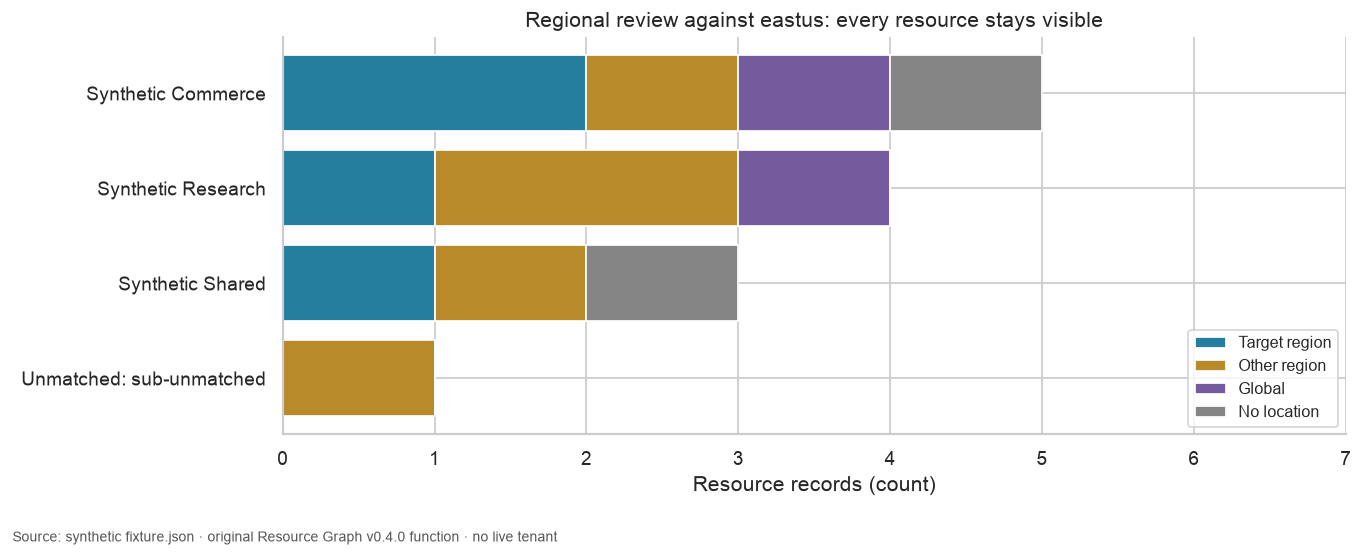

In [13]:
display(summary)
s=summary.iloc[0];regional=int(s.in_target+s.other_region)
assert s.total==int(availability.loc[availability.dataset=="resources","rows"].iloc[0])
assert regional+s.global_resources+s.missing_location==s.total
rate=f"{s.other_region/regional:.1%}" if regional else "unavailable (no regional resources)"
prose(f"The left join retains **all {int(s.total)} resources**, including **{int(s.unmatched)} without a subscription label**. "
      f"Of **{regional} regional resources**, **{int(s.other_region)} ({rate})** lie outside `{TARGET_REGION}`. "
      f"The **{int(s.global_resources)} global** and **{int(s.missing_location)} missing-location** records remain separate, outside that denominator.")
plot=by_subscription.pivot_table(index="subscription_label",columns="location_category",values="resources",aggfunc="sum",fill_value=0).reindex(columns=STATES,fill_value=0)
fig,ax=plt.subplots(figsize=(11,4.7));left=np.zeros(len(plot));y=np.arange(len(plot))
for state in STATES:
    ax.barh(y,plot[state],left=left,label=state,color=COLORS[state]);left+=plot[state].to_numpy()
ax.set_yticks(y,plot.index);ax.invert_yaxis()
ax.set(xlabel="Resource records (count)",xlim=(0,left.max()+2),title=f"Regional review against {TARGET_REGION}: every resource stays visible")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True));ax.legend(loc="lower right",fontsize=9);finish(fig)

## Separate page packing from inventory content

For this fixture, each non-terminal response fills its requested page size. SQL can therefore predict the two scans' request counts as `ceil(resource_rows / page_size) + ceil(subscription_rows / page_size)`. The chart compares that model with the trace from the actual run.

These are **fixture request counts**, not a live latency or quota benchmark. Real services may return smaller pages or incur authentication, retries and other requests. The worker's purpose is to follow continuation tokens, not assume that one page is the whole result.

In [14]:
%%sql page_model <<
SELECT page_size,
       ceil((SELECT count(*) FROM resources)::DOUBLE/page_size)::INTEGER AS resource_requests,
       ceil((SELECT count(*) FROM subscriptions)::DOUBLE/page_size)::INTEGER AS subscription_requests
FROM range(1,11) p(page_size) ORDER BY page_size;

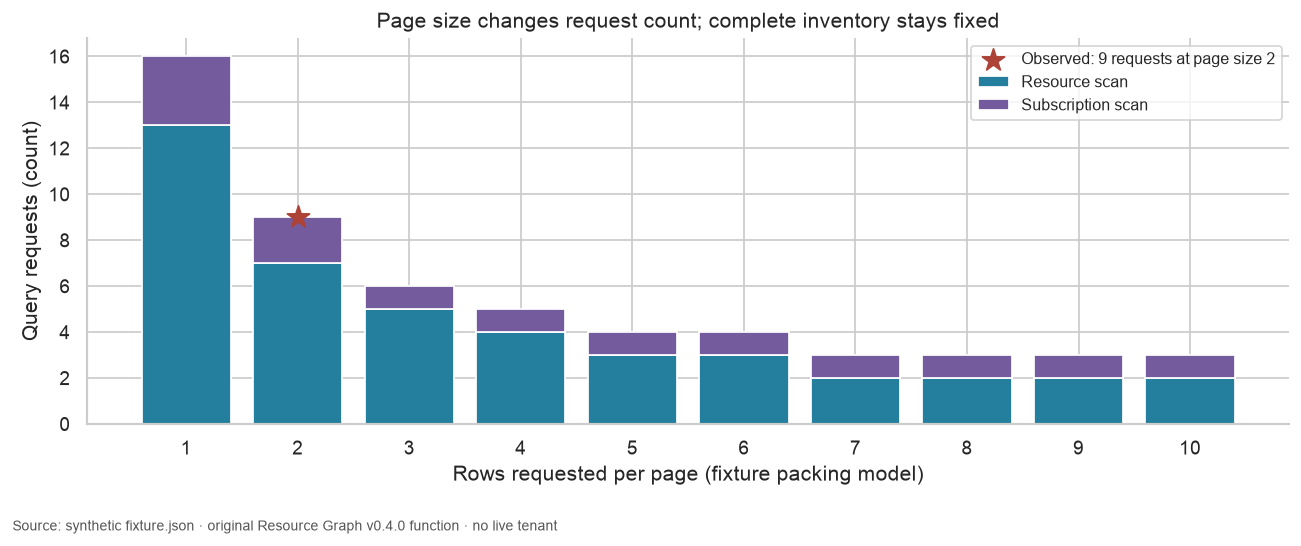

In [15]:
fig,ax=plt.subplots(figsize=(10.5,4.6))
ax.bar(page_model.page_size,page_model.resource_requests,label="Resource scan",color="#247f9e")
ax.bar(page_model.page_size,page_model.subscription_requests,bottom=page_model.resource_requests,label="Subscription scan",color="#745b9e")
if PAGE_SIZE <= 10:
    ax.scatter([PAGE_SIZE],[len(requests)],marker="*",s=180,color="#ad4336",zorder=3,label=f"Observed: {len(requests)} requests at page size {PAGE_SIZE}")
else:
    ax.text(.98,.95,f"Observed at page size {PAGE_SIZE}: {len(requests)} requests",ha="right",va="top",transform=ax.transAxes)
ax.set(xlabel="Rows requested per page (fixture packing model)",ylabel="Query requests (count)",xticks=range(1,11),
       title="Page size changes request count; complete inventory stays fixed")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True));ax.legend(loc="upper right",fontsize=9);finish(fig)

## One change to test

Change only **`PAGE_SIZE` from `2` to `5`**, keeping `TARGET_REGION` fixed. Predict fewer requests with the same resource count, regional denominator, missing-location count and unmatched label. Compare both the fixture hash and returned-row fingerprint; both should match. The bar chart should remain unchanged while the observed marker moves on the page-packing chart.

Use the separate-output command in the [README](README.md), then restore **`PAGE_SIZE = 2`**. This experiment tests the real worker's pagination and mapping against a fixed synthetic inventory. Live queries additionally depend on authorization scope, service semantics, indexing freshness and independently timed scans.

In [16]:
con.close()
fixture_secret_directory.cleanup()
scratch.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and fixture design](README.md)